### Top Rows

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

# -------------------------------------------------
# 1. Replace "x" with 1800 in ORIGINAL df (in place)
# -------------------------------------------------

file_path = "results-filtered.xlsx"
df = pd.read_excel(file_path, sheet_name="all")
df = df.rename(columns=lambda c: c.replace("-total", ""))

sp_noAltRB = ["UMKP-S", "UMKP-P"]
sp_AltRB = ["UMKPT"]
dense = ["kPEX", "kPEX-S", "kPEX-P"]

sparse = sp_AltRB + sp_noAltRB
all_algos = sparse + dense

df[all_algos] = df[all_algos].replace("x", 1800).apply(pd.to_numeric)


In [12]:
df["sparse_min"] = df[sparse].min(axis=1)
df["dense_min"] = df[dense].min(axis=1)

df["ratio"] = np.maximum(df["sparse_min"], df["dense_min"]) / np.minimum(df["sparse_min"], df["dense_min"])

filtered_rows = df[
    (df["sparse_min"] > 1) &
    (df["dense_min"] > 1) &
    (df["ratio"] >= 10)
].sort_values(by="ratio", ascending=False).copy()

# Split into two tables
sparse_wins_table = filtered_rows[filtered_rows["sparse_min"] < filtered_rows["dense_min"]]
dense_wins_table  = filtered_rows[filtered_rows["dense_min"] < filtered_rows["sparse_min"]]

total = len(filtered_rows)

display(Markdown(f"""
## Experiment Summary
### Filtered rows: **{total}**
- Sparse faster: **{len(sparse_wins_table)}**
- Dense faster: **{len(dense_wins_table)}**
"""))

display(Markdown("## Sparse Wins"))
print(sparse_wins_table[["dataset", "k", "sparse_min", "dense_min", "ratio"]])

display(Markdown("## Dense Wins"))
print(dense_wins_table[["dataset", "k", "sparse_min", "dense_min", "ratio"]])


## Experiment Summary
### Filtered rows: **195**
- Sparse faster: **84**
- Dense faster: **111**


## Sparse Wins

                dataset   k  sparse_min  dense_min        ratio
4028   TSOPF_RS_b300_c3   6    1.031971  1800.0000  1744.235061
4040   TSOPF_RS_b678_c1  10    1.604391  1800.0000  1121.921028
4041   TSOPF_RS_b678_c1  20    1.891792  1800.0000   951.478810
4022  TSOPF_RS_b2383_c1  10    2.388061  1800.0000   753.749590
4023  TSOPF_RS_b2383_c1  20    2.443003  1800.0000   736.798113
...                 ...  ..         ...        ...          ...
1782             IG5-15  10  155.578680  1800.0000    11.569709
1211               ESOC   9  157.542527  1800.0000    11.425486
3957   TSOPF_FS_b39_c19   2    7.414656    80.1982    10.816173
3917      TSOPF_FS_b300   2  166.528864  1800.0000    10.808937
3977    TSOPF_FS_b39_c7   2    1.075077    11.5656    10.757927

[84 rows x 5 columns]


## Dense Wins

               dataset   k   sparse_min  dense_min        ratio
2064         Maragal_6   9  1800.000000     1.2795  1406.799531
3998  TSOPF_RS_b162_c3  10  1800.000000     1.3062  1378.043179
4005  TSOPF_RS_b162_c4  20  1800.000000     1.4246  1263.512565
4004  TSOPF_RS_b162_c4  10  1800.000000     1.4672  1226.826609
3999  TSOPF_RS_b162_c3  20  1413.009546     1.2744  1108.764553
...                ...  ..          ...        ...          ...
1071       edit-frwiki   9   309.850472    29.5241    10.494832
911       delicious-ui   6  1047.161841   100.6102    10.408108
487          bibd_17_8  20    75.009932     7.2134    10.398693
2551        p-hat700-1   2    76.610808     7.4672    10.259643
3914  TSOPF_FS_b162_c4  10   632.471769    62.6977    10.087639

[111 rows x 5 columns]


### Winning Algorithm Counts

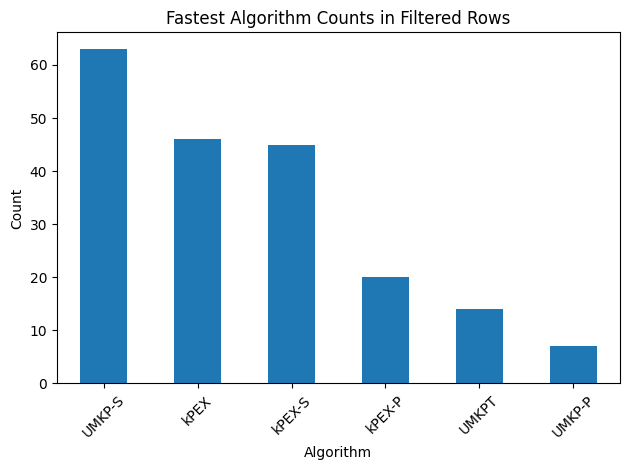

In [13]:
# algorithm that is fastest per row
filtered_rows["fastest_algo"] = filtered_rows[all_algos].idxmin(axis=1)

# count occurrences
algo_counts = filtered_rows["fastest_algo"].value_counts()

algo_counts.plot(kind="bar")

plt.xlabel("Algorithm")
plt.ylabel("Count")
plt.title("Fastest Algorithm Counts in Filtered Rows")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

### Varying Ratio Threshold

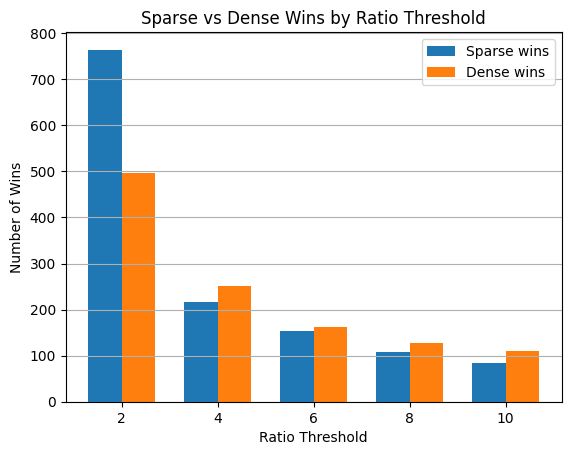

In [14]:
ratio_thresholds = [2, 4, 6, 8, 10]

sparse_wins_list = []
dense_wins_list = []

df["ratio"] = np.maximum(df["sparse_min"], df["dense_min"]) / np.minimum(df["sparse_min"], df["dense_min"])

for r in ratio_thresholds:
    filtered_rows = df[
        (df["sparse_min"] > 1) &
        (df["dense_min"] > 1) &
        (df["ratio"] >= r)
    ]

    total = len(filtered_rows)
    sparse_wins = (filtered_rows["sparse_min"] < filtered_rows["dense_min"]).sum()
    dense_wins = total - sparse_wins

    sparse_wins_list.append(sparse_wins)
    dense_wins_list.append(dense_wins)

# Bar chart
x = np.arange(len(ratio_thresholds))
width = 0.35

plt.figure()
plt.bar(x - width/2, sparse_wins_list, width, label="Sparse wins")
plt.bar(x + width/2, dense_wins_list, width, label="Dense wins")

plt.xticks(x, ratio_thresholds)
plt.xlabel("Ratio Threshold")
plt.ylabel("Number of Wins")
plt.title("Sparse vs Dense Wins by Ratio Threshold")
plt.legend()
plt.grid(axis="y")

plt.show()